# Analyse Exploratoire

## Import des modules

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns 

## Première analyse

In [2]:
building_consumption = pd.read_csv("2016_Building_Energy_Benchmarking.csv")

In [3]:
# On regarde comment un batiment est défini dans ce jeu de données 
pd.set_option('display.max_columns', None)
building_consumption.head()
#building_consumption

,OSEBuildingID,DataYear,BuildingType,PrimaryPropertyType,PropertyName,Address,City,State,ZipCode,TaxParcelIdentificationNumber,CouncilDistrictCode,Neighborhood,Latitude,Longitude,YearBuilt,NumberofBuildings,NumberofFloors,PropertyGFATotal,PropertyGFAParking,PropertyGFABuilding(s),ListOfAllPropertyUseTypes,LargestPropertyUseType,LargestPropertyUseTypeGFA,SecondLargestPropertyUseType,SecondLargestPropertyUseTypeGFA,ThirdLargestPropertyUseType,ThirdLargestPropertyUseTypeGFA,YearsENERGYSTARCertified,ENERGYSTARScore,SiteEUI(kBtu/sf),SiteEUIWN(kBtu/sf),SourceEUI(kBtu/sf),SourceEUIWN(kBtu/sf),SiteEnergyUse(kBtu),SiteEnergyUseWN(kBtu),SteamUse(kBtu),Electricity(kWh),Electricity(kBtu),NaturalGas(therms),NaturalGas(kBtu),DefaultData,Comments,ComplianceStatus,Outlier,TotalGHGEmissions,GHGEmissionsIntensity
0,1,2016,NonResidential,Hotel,Mayflower park hotel,405 Olive way,Seattle,WA,98101.0,0659000030,7,DOWNTOWN,47.61220,-122.33799,1927,1.0,12,88434,0,88434,Hotel,Hotel,88434.0,NaN,NaN,NaN,NaN,NaN,60.0,81.699997,84.300003,182.500000,189.000000,7226362.5,7456910.0,2003882.00,1.156514e+06,3946027.0,12764.52930,1276453.0,False,NaN,Compliant,NaN,249.98,2.83
1,2,2016,NonResidential,Hotel,Paramount Hotel,724 Pine street,Seattle,WA,98101.0,0659000220,7,DOWNTOWN,47.61317,-122.33393,1996,1.0,11,103566,15064,88502,"Hotel, Parking, Restaurant",Hotel,83880.0,Parking,15064.0,Restaurant,4622.0,NaN,61.0,94.800003,97.900002,176.100006,179.399994,8387933.0,8664479.0,0.00,9.504252e+05,3242851.0,51450.81641,5145082.0,False,NaN,Compliant,NaN,295.86,2.86
2,3,2016,NonResidential,Hotel,5673-The Westin Seattle,1900 5th Avenue,Seattle,WA,98101.0,0659000475,7,DOWNTOWN,47.61393,-122.33810,1969,1.0,41,956110,196718,759392,Hotel,Hotel,756493.0,NaN,NaN,NaN,NaN,NaN,43.0,96.000000,97.699997,241.899994,244.100006,72587024.0,73937112.0,21566554.00,1.451544e+07,49526664.0,14938.00000,1493800.0,False,NaN,Compliant,NaN,2089.28,2.19
3,5,2016,NonResidential,Hotel,HOTEL MAX,620 STEWART ST,Seattle,WA,98101.0,0659000640,7,DOWNTOWN,47.61412,-122.33664,1926,1.0,10,61320,0,61320,Hotel,Hotel,61320.0,NaN,NaN,NaN,NaN,NaN,56.0,110.800003,113.300003,216.199997,224.000000,6794584.0,6946800.5,2214446.25,8.115253e+05,2768924.0,18112.13086,1811213.0,False,NaN,Compliant,NaN,286.43,4.67
4,8,2016,NonResidential,Hotel,WARWICK SEATTLE HOTEL (ID8),401 LENORA ST,Seattle,WA,98121.0,0659000970,7,DOWNTOWN,47.61375,-122.34047,1980,1.0,18,175580,62000,113580,"Hotel, Parking, Swimming Pool",Hotel,123445.0,Parking,68009.0,Swimming Pool,0.0,NaN,75.0,114.800003,118.699997,211.399994,215.600006,14172606.0,14656503.0,0.00,1.573449e+06,5368607.0,88039.98438,8803998.0,False,NaN,Compliant,NaN,505.01,2.88


In [4]:
# On regarde le nombre de valeurs manquantes par colonne ainsi que leur type 
building_consumption.info()

<class 'pandas.DataFrame'>
RangeIndex: 3376 entries, 0 to 3375
Data columns (total 46 columns):
 #   Column                           Non-Null Count  Dtype  
---  ------                           --------------  -----  
 0   OSEBuildingID                    3376 non-null   int64  
 1   DataYear                         3376 non-null   int64  
 2   BuildingType                     3376 non-null   str    
 3   PrimaryPropertyType              3376 non-null   str    
 4   PropertyName                     3376 non-null   str    
 5   Address                          3376 non-null   str    
 6   City                             3376 non-null   str    
 7   State                            3376 non-null   str    
 8   ZipCode                          3360 non-null   float64
 9   TaxParcelIdentificationNumber    3376 non-null   str    
 10  CouncilDistrictCode              3376 non-null   int64  
 11  Neighborhood                     3376 non-null   str    
 12  Latitude                       

#### Tri des colonnes

A réaliser : 
- Une analyse descriptive des données, y compris une explication du sens des colonnes gardées, des arguments derrière la suppression de lignes ou de colonnes, des statistiques descriptives et des visualisations pertinentes.

Qelques pistes d'analyse : 

* Identifier les colonnes avec une majorité de valeurs manquantes ou constantes en utilisant la méthode value_counts() de Pandas
* Mettre en evidence les différences entre les immeubles mono et multi-usages
* Utiliser des pairplots et des boxplots pour faire ressortir les outliers ou des batiments avec des valeurs peu cohérentes d'un point de vue métier 

Pour vous inspirer, ou comprendre l'esprit recherché dans une analyse exploratoire, vous pouvez consulter ce notebook en ligne : https://www.kaggle.com/code/pmarcelino/comprehensive-data-exploration-with-python. Il ne s'agit pas d'un modèle à suivre à la lettre ni d'un template d'analyses attendues pour ce projet. 

In [5]:
# Afficher les colonnes du jeu de données
liste_colonnes = building_consumption.columns
print (liste_colonnes)

Index(['OSEBuildingID', 'DataYear', 'BuildingType', 'PrimaryPropertyType',
       'PropertyName', 'Address', 'City', 'State', 'ZipCode',
       'TaxParcelIdentificationNumber', 'CouncilDistrictCode', 'Neighborhood',
       'Latitude', 'Longitude', 'YearBuilt', 'NumberofBuildings',
       'NumberofFloors', 'PropertyGFATotal', 'PropertyGFAParking',
       'PropertyGFABuilding(s)', 'ListOfAllPropertyUseTypes',
       'LargestPropertyUseType', 'LargestPropertyUseTypeGFA',
       'SecondLargestPropertyUseType', 'SecondLargestPropertyUseTypeGFA',
       'ThirdLargestPropertyUseType', 'ThirdLargestPropertyUseTypeGFA',
       'YearsENERGYSTARCertified', 'ENERGYSTARScore', 'SiteEUI(kBtu/sf)',
       'SiteEUIWN(kBtu/sf)', 'SourceEUI(kBtu/sf)', 'SourceEUIWN(kBtu/sf)',
       'SiteEnergyUse(kBtu)', 'SiteEnergyUseWN(kBtu)', 'SteamUse(kBtu)',
       'Electricity(kWh)', 'Electricity(kBtu)', 'NaturalGas(therms)',
       'NaturalGas(kBtu)', 'DefaultData', 'Comments', 'ComplianceStatus',
       'Outlier

In [6]:
# Analyser chaque colonne, en fonction de l'occurence de ses valeurs.
for data in liste_colonnes:
    value_counts_i = building_consumption[data].value_counts()
    print(f"Colonne : {data}")
    print(f"Nombre de valeurs uniques : {building_consumption[data].nunique()}")
    print(f"Nombre de NaN : {building_consumption[data].isna().sum()}")
    #print(value_counts_i)
    print("-------------------------------")

Colonne : OSEBuildingID
Nombre de valeurs uniques : 3376
Nombre de NaN : 0
-------------------------------
Colonne : DataYear
Nombre de valeurs uniques : 1
Nombre de NaN : 0
-------------------------------
Colonne : BuildingType
Nombre de valeurs uniques : 8
Nombre de NaN : 0
-------------------------------
Colonne : PrimaryPropertyType
Nombre de valeurs uniques : 24
Nombre de NaN : 0
-------------------------------
Colonne : PropertyName
Nombre de valeurs uniques : 3362
Nombre de NaN : 0
-------------------------------
Colonne : Address
Nombre de valeurs uniques : 3354
Nombre de NaN : 0
-------------------------------
Colonne : City
Nombre de valeurs uniques : 1
Nombre de NaN : 0
-------------------------------
Colonne : State
Nombre de valeurs uniques : 1
Nombre de NaN : 0
-------------------------------
Colonne : ZipCode
Nombre de valeurs uniques : 55
Nombre de NaN : 16
-------------------------------
Colonne : TaxParcelIdentificationNumber
Nombre de valeurs uniques : 3268
Nombre de

#### Visualisation

['YearBuilt', 'NumberofBuildings', 'NumberofFloors', 'PropertyGFAParking', 'PropertyGFABuilding(s)', 'LargestPropertyUseTypeGFA', 'SiteEUI(kBtu/sf)', 'SiteEUIWN(kBtu/sf)', 'SourceEUI(kBtu/sf)', 'SourceEUIWN(kBtu/sf)', 'SiteEnergyUseWN(kBtu)', 'SteamUse(kBtu)', 'Electricity(kBtu)', 'NaturalGas(kBtu)', 'GHGEmissionsIntensity', 'TotalGHGEmissions']


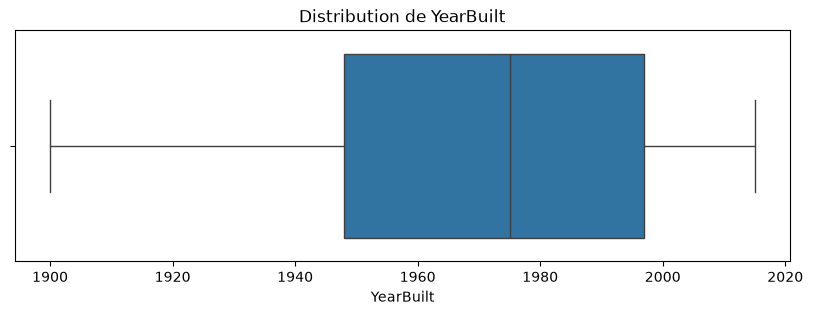

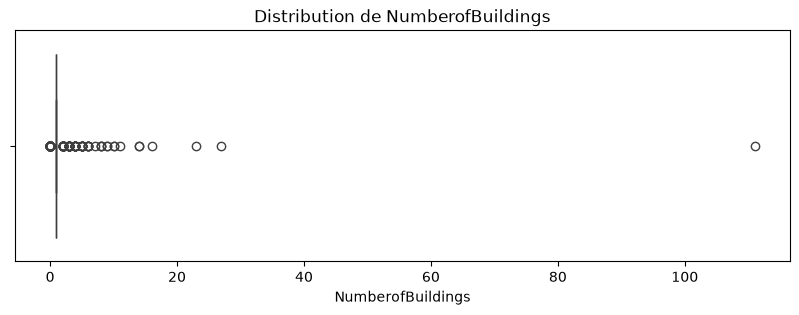

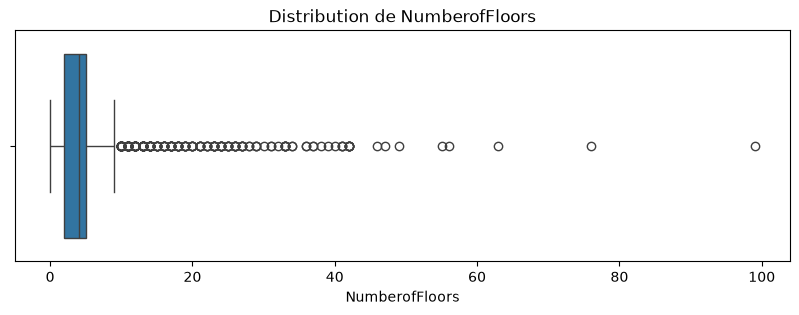

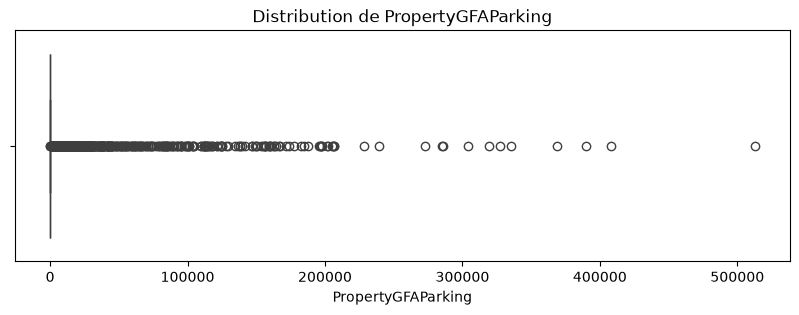

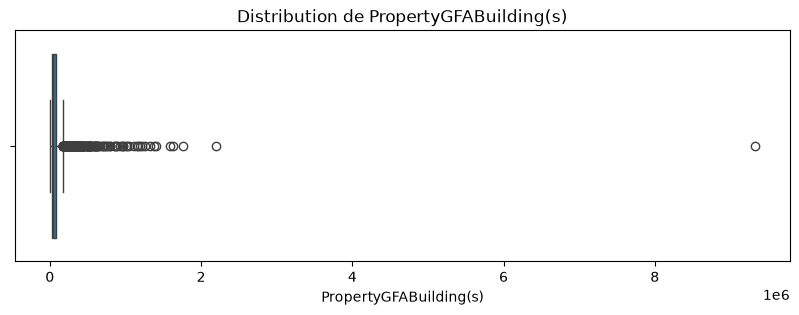

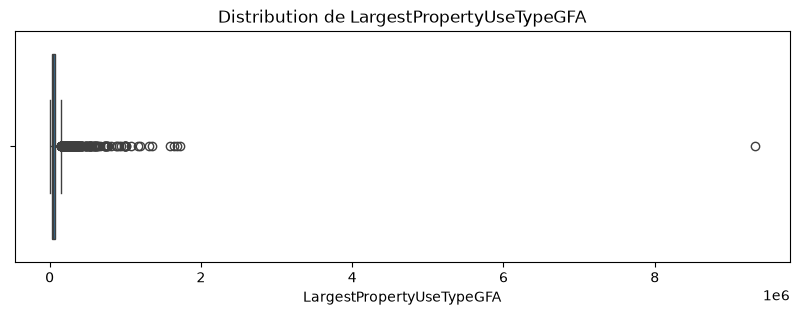

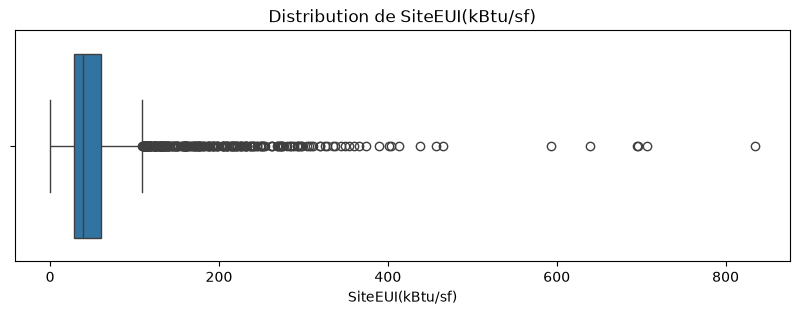

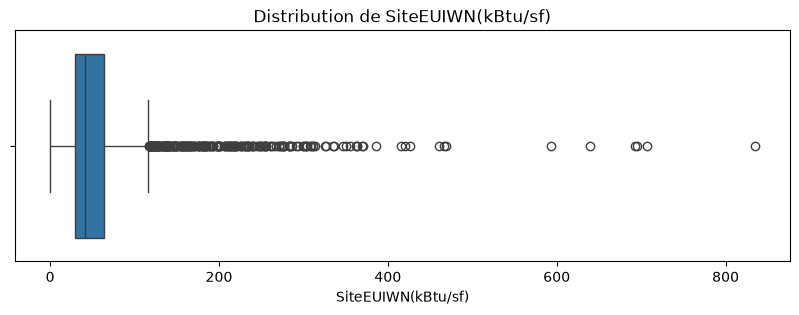

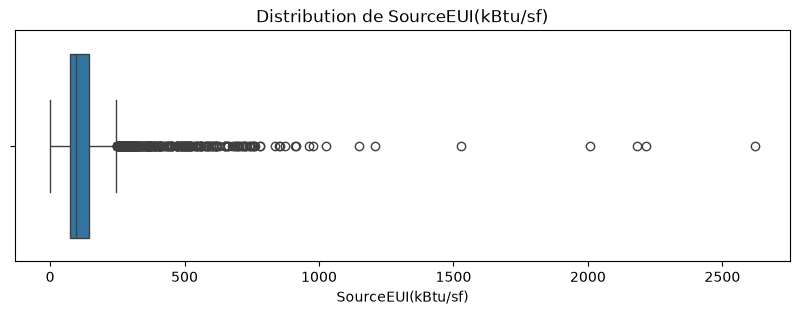

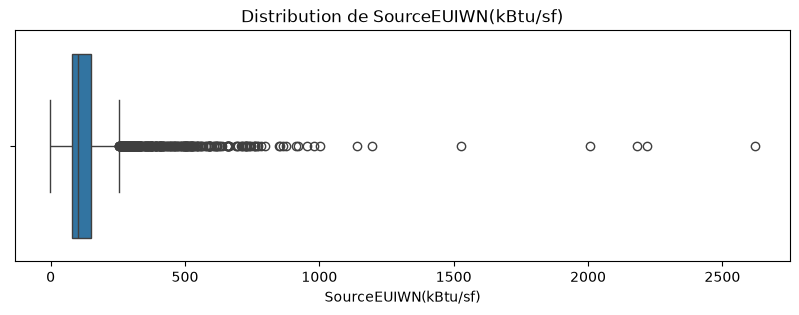

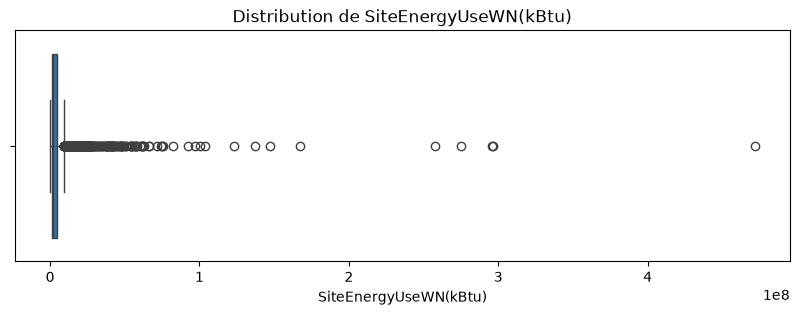

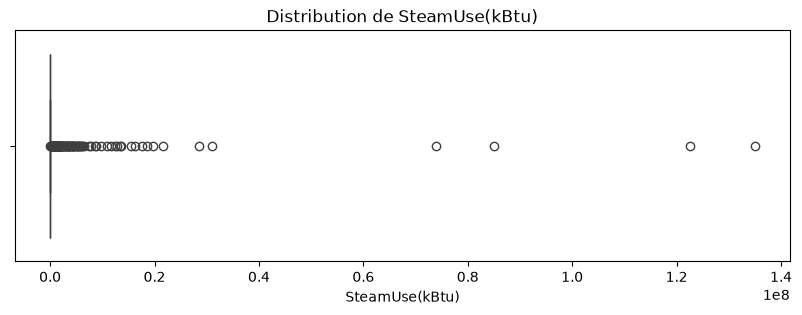

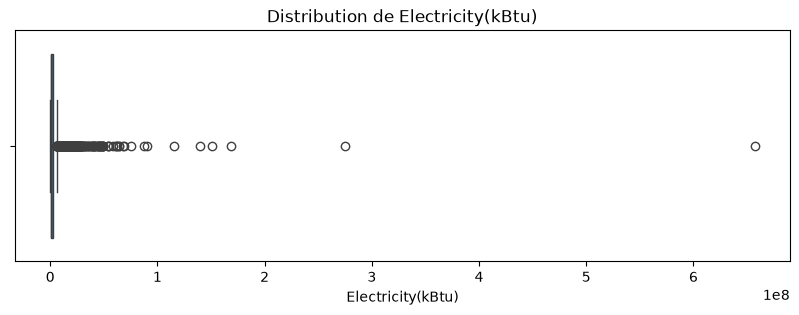

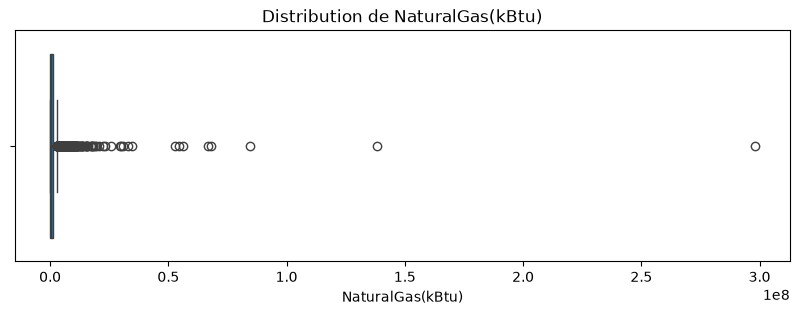

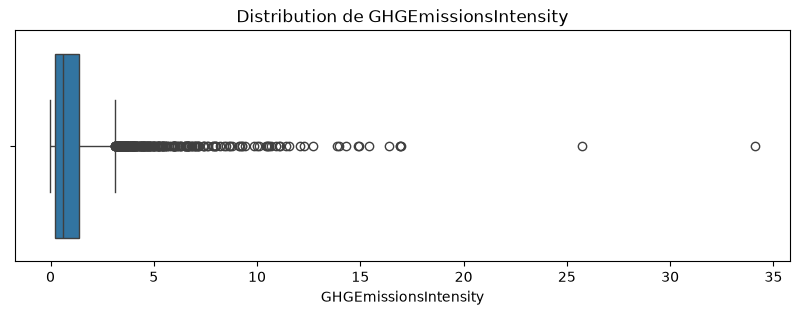

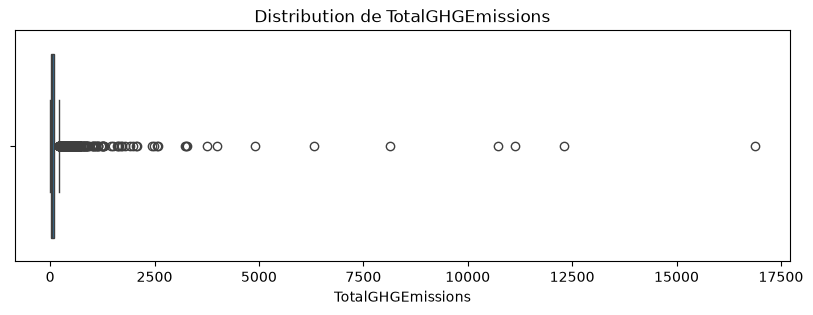

In [7]:
# Voici les colonnes retenues pour l'analyse de l'émission de CO2 des bâtiments :
colonnes_retenues = [
    'BuildingType',
    'PrimaryPropertyType',
    'ZipCode',
    'CouncilDistrictCode',
    'Neighborhood',
    'YearBuilt',
    'NumberofBuildings',
    'NumberofFloors',
    'PropertyGFAParking',
    'PropertyGFABuilding(s)',
    'LargestPropertyUseType',
    'LargestPropertyUseTypeGFA',
    'SiteEUI(kBtu/sf)',
    'SiteEUIWN(kBtu/sf)',
    'SourceEUI(kBtu/sf)',
    'SourceEUIWN(kBtu/sf)',
    'SiteEnergyUseWN(kBtu)',
    'SteamUse(kBtu)',
    'Electricity(kBtu)',
    'NaturalGas(kBtu)',
    'GHGEmissionsIntensity' ,
    'TotalGHGEmissions'
]

# Faire des graphiques pour aprécier la distribution des données, et leur outliers
# Sélection des colonnes numériques
df = building_consumption[colonnes_retenues]
colonnes_numeriques = df.select_dtypes(include='number').columns.tolist()

# Exclure les numériques qui ne représentent pas une mesure, comme le code postal et le département
colonnes_numeriques = [
    col for col in colonnes_numeriques
    if col not in ['ZipCode', 'CouncilDistrictCode']
]
print(colonnes_numeriques)

# On peut maintenant visualiser la distribution des colonnes numériques avec des boxplots
for col in colonnes_numeriques:

    plt.figure(figsize=(10, 3))

    sns.boxplot(x=df[col])

    plt.title(f'Distribution de {col}')
    plt.xlabel(col)

    plt.show()


Il y a énormement de données aberrantes, très peu de colonnes seraient exploitables sans un tri sur les valeurs (trier les lignes)

#### Tri des lignes

##### Première passe

1460


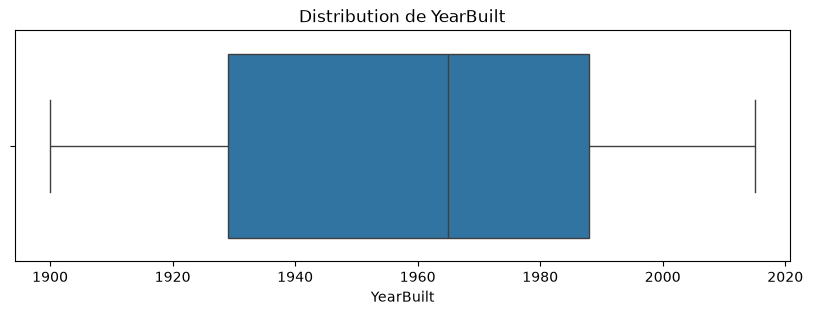

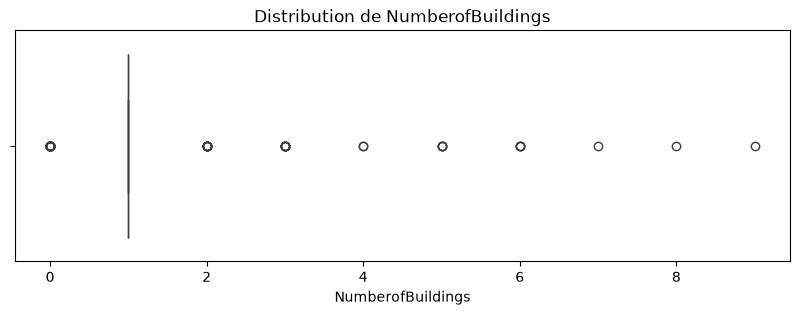

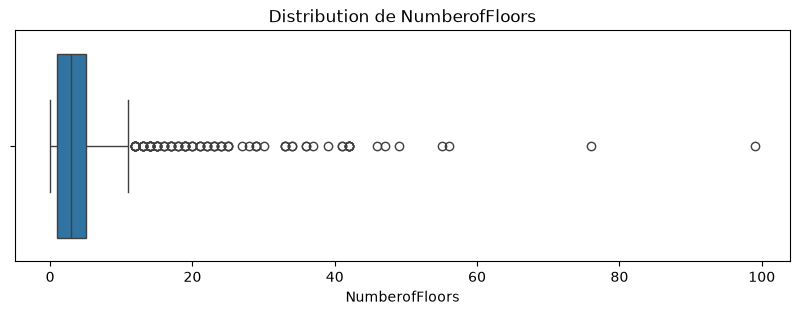

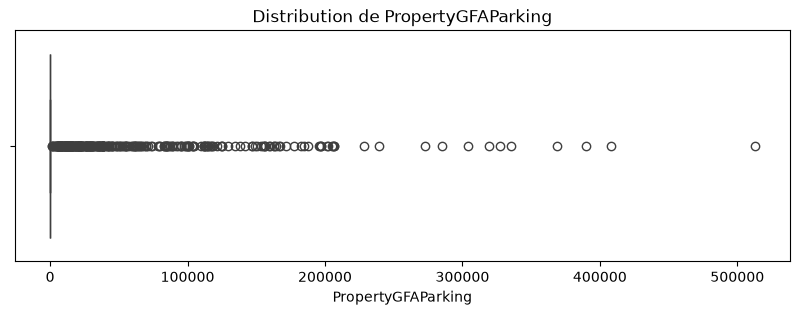

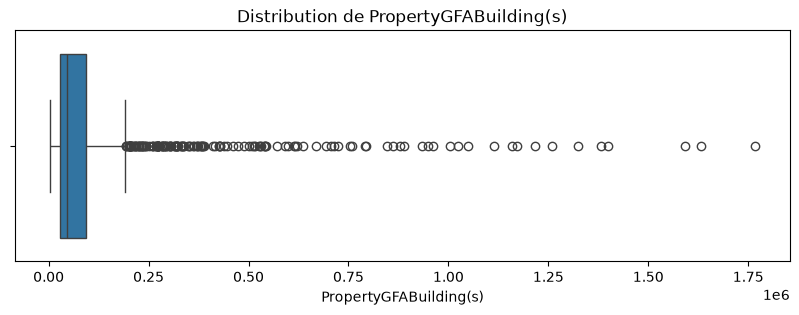

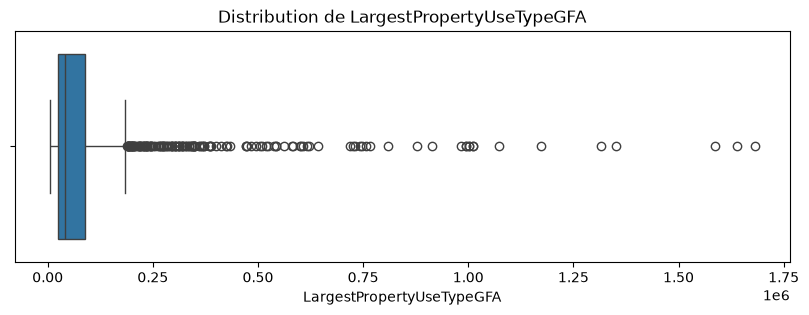

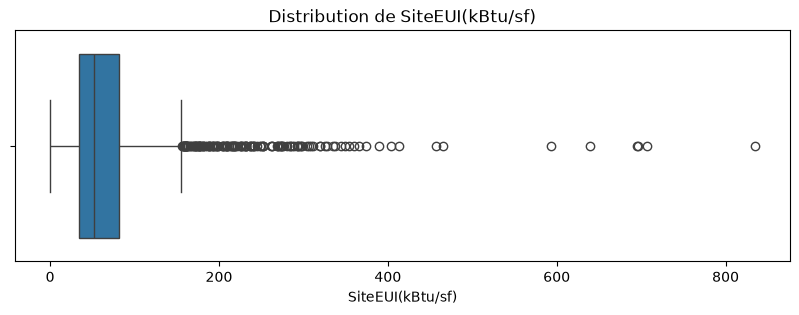

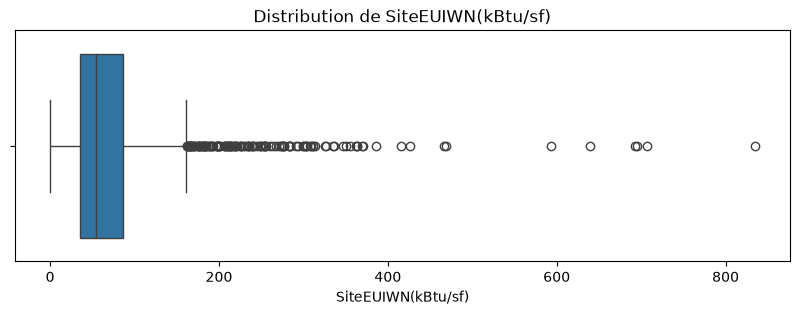

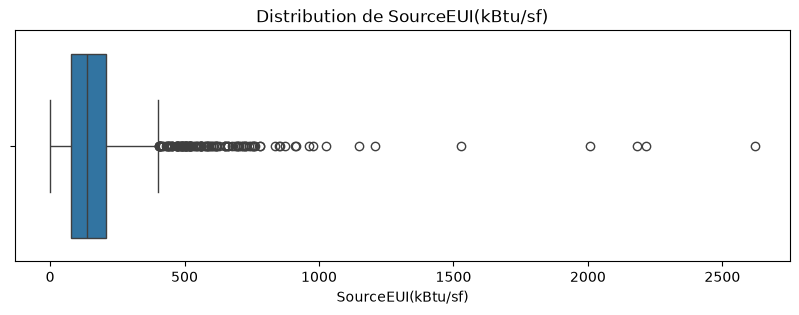

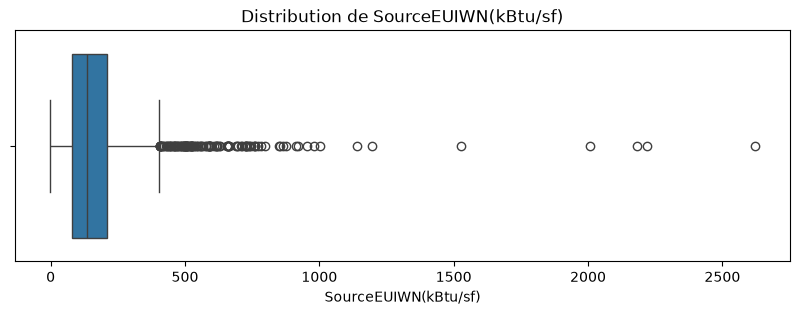

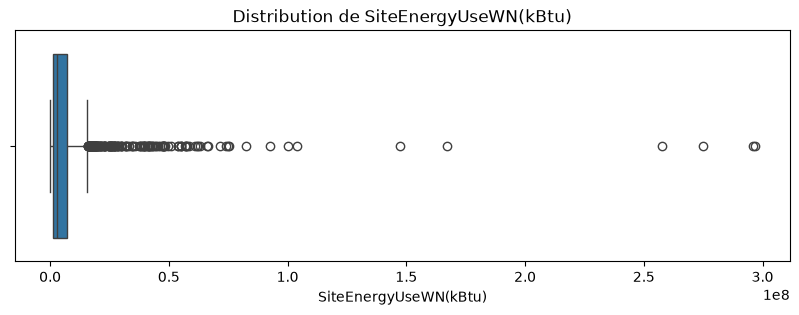

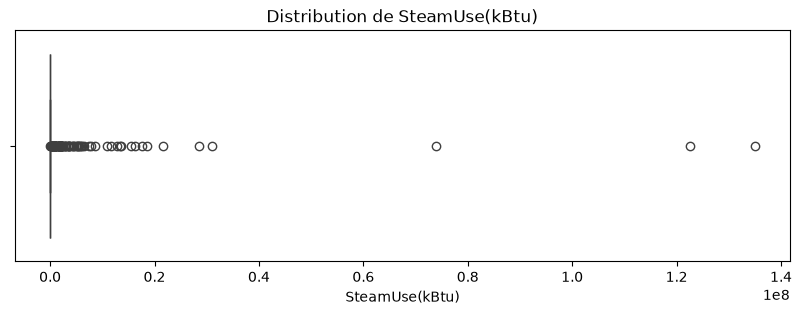

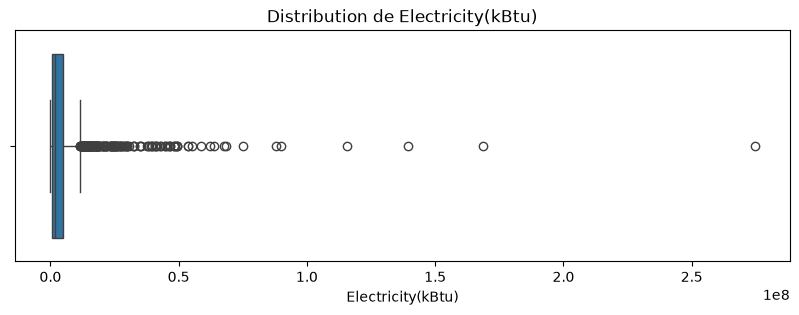

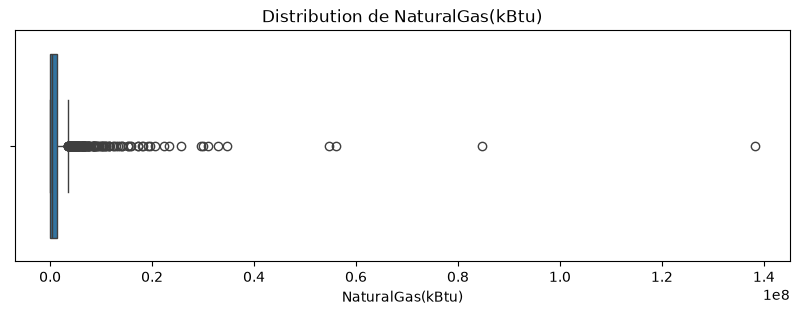

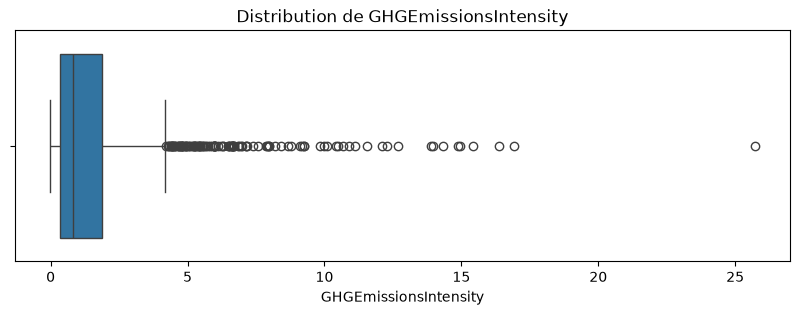

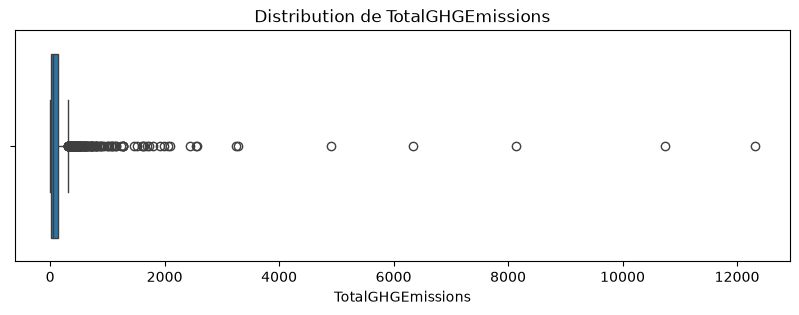

In [ ]:
# Conformément à l'énoncé, on ne gardera que les lignes concernant les bâtiments non destinés à l’habitation
# (on passe de 3376 lignes à 1460)
df = df[df['BuildingType'] == 'NonResidential'].copy()
print(df.shape[0])

# Visualisons de nouveau
for col in colonnes_numeriques:

    plt.figure(figsize=(10, 3))

    sns.boxplot(x=df[col])

    plt.title(f'Distribution de {col}')
    plt.xlabel(col)

    plt.show()

# Après avoir visualisé de nouveau les boxplots, je m'intéresse désormais à la nature réelle derrière les valeurs aberrantes.
# Je considère qu'aucune valeur n'est aberrante finalement pour :
#   - le nombre de bâtiments
#   - le nombre d'étages 
# Je considère également que les données énergétiques nécessitent un croisement de données (nuage de points)
# donc je ne les supprime pas.
# Enfin, concernant les données de surface, je pense qu'il faudrait refaire un boxplot après avoir supprimé les zéros, car cela fausse la distribution. 
# Et fausse par conséquent l'identification des outliers.


In [9]:
# On va décrire quelques colonnes pour mieux comprendre les données et leur distribution
colonnes_a_decrire = [
    'NumberofBuildings',
    'SourceEUI(kBtu/sf)',
    'SiteEnergyUseWN(kBtu)',
    'SteamUse(kBtu)',
    'Electricity(kBtu)',
    'NaturalGas(kBtu)',
    'GHGEmissionsIntensity'
]

df[colonnes_a_decrire].describe()

,NumberofBuildings,SourceEUI(kBtu/sf),SiteEnergyUseWN(kBtu),SteamUse(kBtu),Electricity(kBtu),NaturalGas(kBtu),GHGEmissionsIntensity
count,1458.000000,1458.000000,1.457000e+03,1.458000e+03,1.458000e+03,1.458000e+03,1458.000000
mean,1.034294,180.283059,7.842724e+06,4.998068e+05,5.514732e+06,1.681726e+06,1.543018
std,0.540904,192.748456,1.925848e+07,5.448602e+06,1.329224e+07,5.646165e+06,2.154939
min,0.000000,0.000000,0.000000e+00,0.000000e+00,-1.154170e+05,0.000000e+00,-0.020000
25%,1.000000,76.674999,1.262256e+06,0.000000e+00,7.042265e+05,0.000000e+00,0.330000
50%,1.000000,136.000000,2.737986e+06,0.000000e+00,1.658950e+06,4.187330e+05,0.800000
75%,1.000000,207.700001,7.070998e+06,0.000000e+00,5.076646e+06,1.380787e+06,1.870000
max,9.000000,2620.000000,2.966717e+08,1.349435e+08,2.745325e+08,1.381912e+08,25.710000


##### Deuxième passe

In [10]:
# Exclure les lignes avec des valeurs nulles pour les colonnes de surface
# colonnes_surface = ['PropertyGFAParking', 'PropertyGFABuilding(s)', 'LargestPropertyUseTypeGFA']
# for col in colonnes_surface:
#     df = df[df[col] != 0]   

# Visualiser de nouveau les boxplots pour les surfaces
# for col in colonnes_surface:
#     plt.figure(figsize=(10, 3))
#     sns.boxplot(x=df[col])
#     plt.title(f'Distribution de {col}')
#     plt.xlabel(col)
#     plt.show()

# Après considération, ces zéros ne justifient pas de retirer les lignes correspondantes, dans un premier temps.
# En effet, je préfère tester déjà un premier modèle, 
# et aviser ensuite de remplacer les zéros par NaN, une valeur médiane/moyenne 
# ou encore de supprimer les lignes correspondantes.

# Bien que cela améliore en effet la détection des "vraies" valeurs aberrantes, supprimer les lignes pourraient dégrader les prédictions du modèle.

#### Première modélisation

##### Import des modules 

In [11]:
#Selection
from sklearn.model_selection import (
    train_test_split,
    GridSearchCV, 
    cross_validate,
)
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error 
from sklearn.inspection import permutation_importance

#Preprocess
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import LabelEncoder, OneHotEncoder, StandardScaler

#Modèles
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.svm import SVR
from sklearn.ensemble import RandomForestRegressor


##### Entrainer un modèle

In [ ]:
# Pour la régression, supprimer les lignes incomplètes (NaN) est une approche simple et efficace.
# (Finalement, ne pas supprimer également les valeurs nulles concernant les variable de surface)
# (Donc 1452 lignes restantes sur 3376, au lieu de 320)
df_num = df[colonnes_numeriques].dropna()
print(df_num.shape[0])

# Définir les variables prédictives et la variable cible
X = df_num.drop(columns="TotalGHGEmissions")
y = df_num.TotalGHGEmissions

# Segmenter les données en ensembles d'entraînement et de test (avec un random_state fixe pour la reproductibilité)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42)

# Commencer par un modèle de régression linéaire simple pour établir une base de référence
reg = LinearRegression()

# Entraîner le modèle
reg.fit(X_train, y_train)

# Mesurer la performance
print(reg.score(X, y))

# Aprécier le poids des coefficients pour chaque variable prédictive
coefficients = pd.DataFrame(reg.coef_, X.columns, columns=['Coefficient'])
print(coefficients)

# Je remarque de nombreuses incohérences à travers ce résultat :
#    - Passer de 3416 lignes à 320 lignes, c'est trop drastique. 
#    - Le score de 0.9999 est bien trop élevé pour être crédible.
#    - Les coefficients sont disproportionnés entre eux, il est nécessaire de standardiser.


1452
0.999999999975491
                            Coefficient
YearBuilt                 -1.389938e-06
NumberofBuildings         -2.704180e-09
NumberofFloors             4.846882e-08
PropertyGFAParking         1.082135e-09
PropertyGFABuilding(s)     2.435640e-09
LargestPropertyUseTypeGFA -1.977028e-09
SiteEUI(kBtu/sf)           1.701135e-06
SiteEUIWN(kBtu/sf)         1.697877e-06
SourceEUI(kBtu/sf)        -3.509483e-07
SourceEUIWN(kBtu/sf)      -5.966161e-07
SiteEnergyUseWN(kBtu)      3.226195e-11
SteamUse(kBtu)             7.718786e-05
Electricity(kBtu)          6.971352e-06
NaturalGas(kBtu)           5.310997e-05
GHGEmissionsIntensity      1.073295e-07


In [13]:
# Passer de 3376 à 320 lignes = ne pas imputer trop rapidement (c'était le cas après avoir supprimé les lignes avec des valeurs nulles pour les colonnes de surface)
# Identifier si colonnes problématiques avec des valeurs nulles ou manquantes : ce n'est pas le cas
print(df[colonnes_numeriques].isnull().mean().sort_values(ascending=False))
print(df[colonnes_numeriques].isna().mean().sort_values(ascending=False))

# Piste pour expliquer le score de 0.9999 : la fuite de données.
# Mais avant ça, on va essayer de retrouver une cohérence entre les coefficients en standardisant les variables prédictives.


LargestPropertyUseTypeGFA    0.004110
SiteEUI(kBtu/sf)             0.002055
SiteEUIWN(kBtu/sf)           0.002055
SiteEnergyUseWN(kBtu)        0.002055
SteamUse(kBtu)               0.001370
SourceEUIWN(kBtu/sf)         0.001370
SourceEUI(kBtu/sf)           0.001370
NumberofBuildings            0.001370
Electricity(kBtu)            0.001370
NaturalGas(kBtu)             0.001370
GHGEmissionsIntensity        0.001370
TotalGHGEmissions            0.001370
PropertyGFABuilding(s)       0.000000
YearBuilt                    0.000000
NumberofFloors               0.000000
PropertyGFAParking           0.000000
dtype: float64
LargestPropertyUseTypeGFA    0.004110
SiteEUI(kBtu/sf)             0.002055
SiteEUIWN(kBtu/sf)           0.002055
SiteEnergyUseWN(kBtu)        0.002055
SteamUse(kBtu)               0.001370
SourceEUIWN(kBtu/sf)         0.001370
SourceEUI(kBtu/sf)           0.001370
NumberofBuildings            0.001370
Electricity(kBtu)            0.001370
NaturalGas(kBtu)             0.0013

In [14]:
# Refaire la régression linéaire après avoir standardisé les variables prédictives
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train_sc = scaler.fit_transform(X_train)   # ajusté sur le train
X_test_sc = scaler.transform(X_test)         # simple application sur le test

reg_sc = LinearRegression()
reg_sc.fit(X_train_sc, y_train)

print("R² train :", reg_sc.score(X_train_sc, y_train))
print("R² test  :", reg_sc.score(X_test_sc, y_test))

coefficients = pd.DataFrame(reg_sc.coef_, index=X.columns, columns=["Coefficient"])
print(coefficients.sort_values("Coefficient", key=abs, ascending=False))

# Conclusion, la standardisation révèle la correlation trop forte entre la consommation d'énergie et la cible (émission CO2)
# Le modèle ne prédit donc rien et applique simplement une formule sur des données d'ailleurs difficiles à avoir en avance de phase d'un projet de construction
# Décision de les retirer

R² train : 0.9999999999787634
R² test  : 0.999999999944039
                           Coefficient
SteamUse(kBtu)              460.624608
NaturalGas(kBtu)            299.172085
Electricity(kBtu)           100.003129
SourceEUI(kBtu/sf)           -0.002629
SiteEnergyUseWN(kBtu)        -0.001945
SourceEUIWN(kBtu/sf)          0.001938
SiteEUI(kBtu/sf)              0.000846
PropertyGFABuilding(s)        0.000371
GHGEmissionsIntensity        -0.000272
NumberofFloors               -0.000182
NumberofBuildings            -0.000178
LargestPropertyUseTypeGFA    -0.000125
SiteEUIWN(kBtu/sf)            0.000086
YearBuilt                    -0.000063
PropertyGFAParking            0.000035


In [15]:
# Retirer les colonnes liées directement à la consomation d'énergie (car liées aussi directement au CO2)
colonnes_a_exclure = [
    "TotalGHGEmissions",
    "GHGEmissionsIntensity",
    "SiteEUI(kBtu/sf)", "SiteEUIWN(kBtu/sf)",
    "SourceEUI(kBtu/sf)", "SourceEUIWN(kBtu/sf)",
    "SiteEnergyUseWN(kBtu)", "Electricity(kBtu)",
    "NaturalGas(kBtu)", "SteamUse(kBtu)",
]

X = df_num.drop(columns=colonnes_a_exclure)
y = df_num["TotalGHGEmissions"]

# Split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42)

# Standardisation (ajustée sur le train uniquement)
scaler = StandardScaler()
X_train_sc = scaler.fit_transform(X_train)
X_test_sc = scaler.transform(X_test)

# Régression
reg_sc = LinearRegression()
reg_sc.fit(X_train_sc, y_train)

print("R² train :", reg_sc.score(X_train_sc, y_train))
print("R² test  :", reg_sc.score(X_test_sc, y_test))

# Coefficients (X est bien un DataFrame, donc X.columns fonctionne)
coefficients = pd.DataFrame(reg_sc.coef_, index=X.columns, columns=["Coefficient"])
print(coefficients.sort_values("Coefficient", key=abs, ascending=False))

R² train : 0.5621794568358698
R² test  : 0.33319120798532365
                           Coefficient
LargestPropertyUseTypeGFA   593.658670
NumberofBuildings           224.071111
PropertyGFABuilding(s)     -166.380631
PropertyGFAParking         -132.819891
NumberofFloors              -94.136808
YearBuilt                     5.408955


##### Maintenant que nous avons un score cohérent

On va faire des graphiques relationnelles de type nuage de points, pour comprendre l'évolution linéaire ou non de chaque paramètre, au regards de l'émission CO2

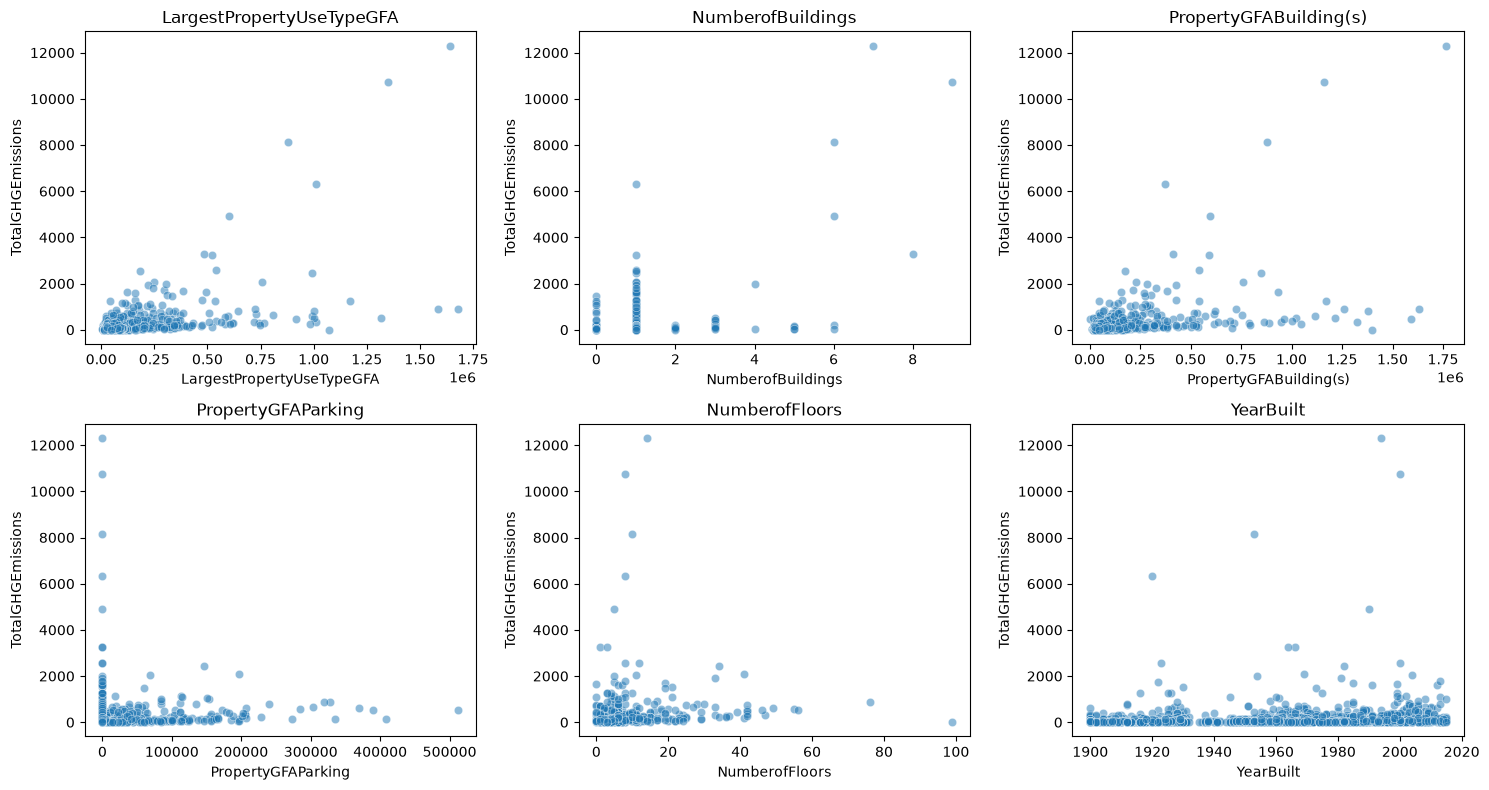

In [16]:
# # Faire des graphiques nuages de points, un par paramètre ci-dessous, en corrélation avec l'émission CO2 : "TotalGHGEmissions"
# LargestPropertyUseTypeGFA   593.658670
# NumberofBuildings           224.071111
# PropertyGFABuilding(s)     -166.380631
# PropertyGFAParking         -132.819891
# NumberofFloors              -94.136808
# YearBuilt                     5.408955

# Variables explicatives (ordre des coefficients)
cols = ["LargestPropertyUseTypeGFA", "NumberofBuildings", "PropertyGFABuilding(s)",
        "PropertyGFAParking", "NumberofFloors", "YearBuilt"]
# Grille 2x3, un nuage de points par variable
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, c in zip(axes.flat, cols):
    sns.scatterplot(data=df, x=c, y="TotalGHGEmissions", alpha=0.5, ax=ax)
    ax.set_title(c)
plt.tight_layout()
plt.show()

Il y a beaucoup de valeurs aberrantes, il est difficile d'aprécier l'évolution des paramètres mais tout de même, à première vue rien n'est linéaire ou polynomiale.
Je pense donc que l'approche de régression "basique" n'est pas la bonne, il faudrait recourrir à d'autre type de modèle comme :
   - Régression "avancée" 
      - Rajouter les varaibles catégorielles, à convertir les catégorie texte en variable numérique
      - Ecarter les outliers, notamment sur la surface de la propriété "largest" et la consommation du batîment sans le parking "PropertyGFA", qui pourraient être linéaires
   - Abres de décisions
   - Réseaux de neuronnes

##### Pour atténuer l'effet des outliers sans les filtrer, passer en log

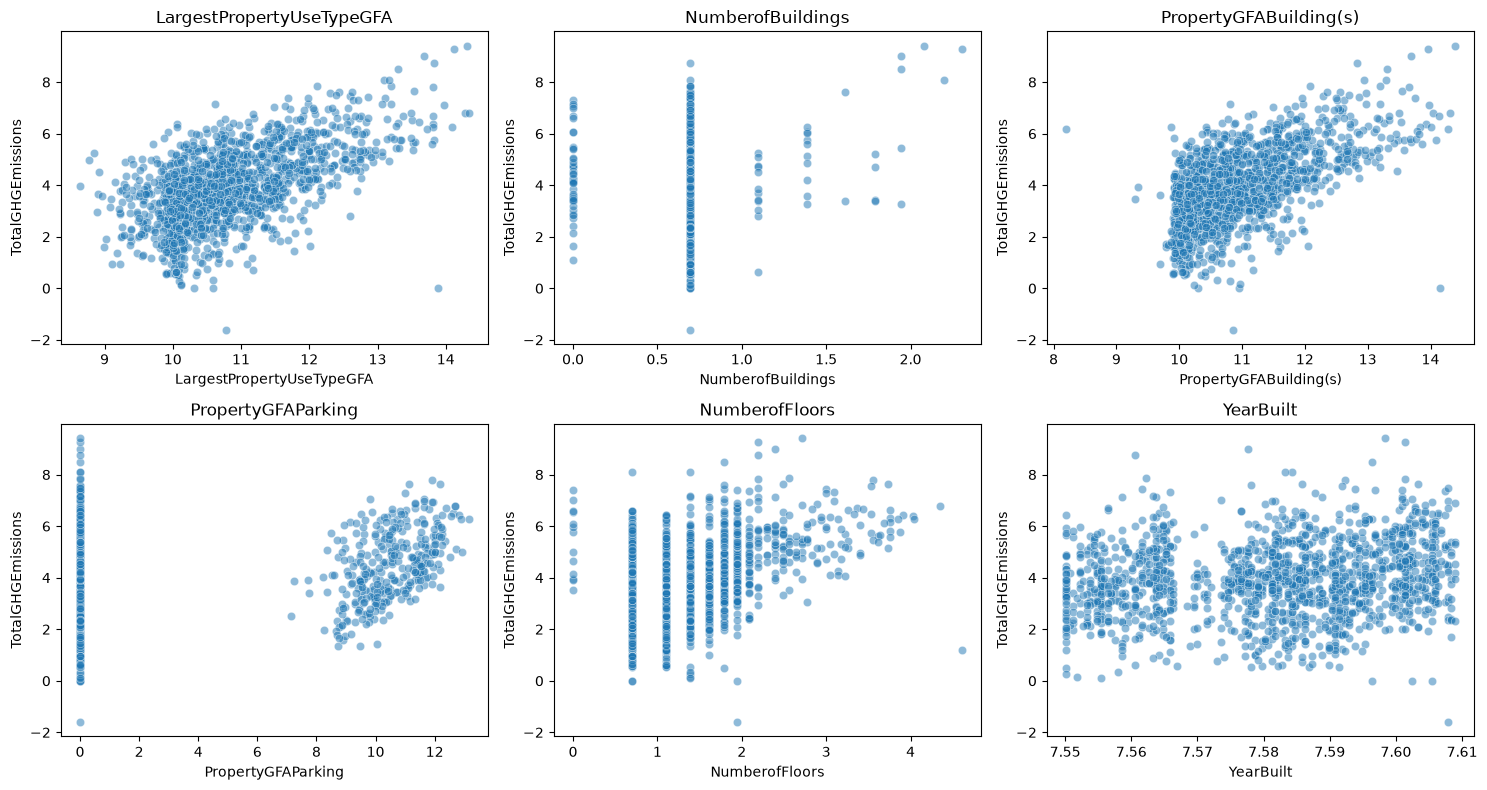

In [17]:
import numpy as np
# Mêmes graphiques en log (log1p gère les zéros)
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, c in zip(axes.flat, cols):
    sns.scatterplot(x=np.log1p(df[c]), y=np.log1p(df["TotalGHGEmissions"]), alpha=0.5, ax=ax)
    ax.set_title(c)
plt.tight_layout()
plt.show()

## Remise en question, Deuxième analyse

Finalement, je vais faire une matrice de corrélation (heatmap) sur l'ensemble de paramètre pour écarter l'effet multi-colinéaire. 

En effet, après le point avec le mentor, je considère finalement que le lien entre la consommation d'énergie et le CO2 n'est pas direct et parfait.

Donc je recommence le tri des paramètres retenus (colonnes), avant de passer à l'étape suivante : Feature Engineering

### Visualisation

> Par défaut, Pandas utilise la corrélation de Pearson.

Les coefficients sont compris entre -1 et +1 :
- +1 : corrélation positive parfaite.
- 0 : absence de corrélation linéaire.
- -1 : corrélation négative parfaite.

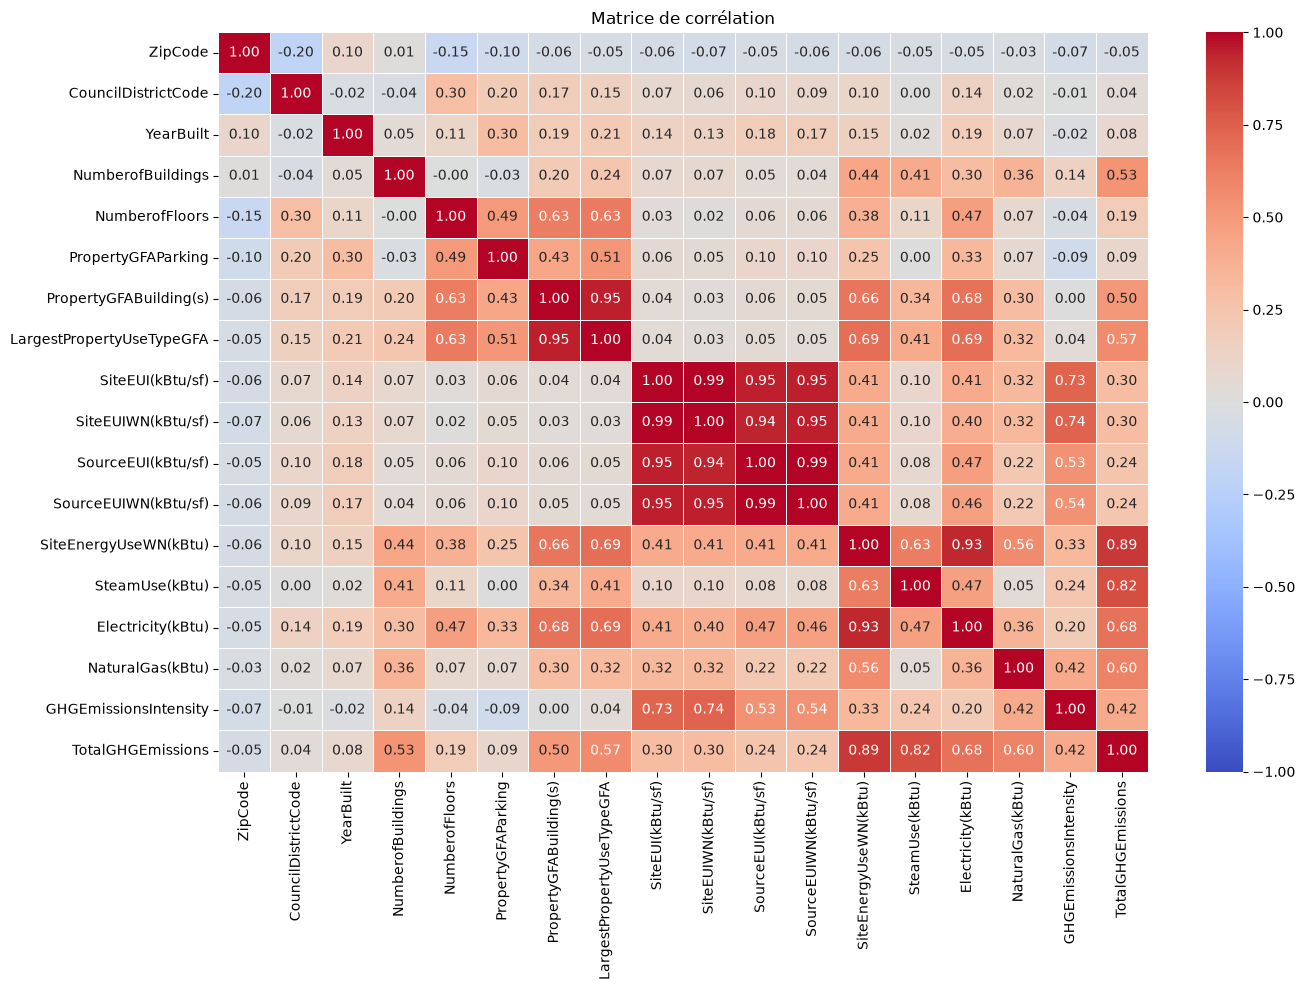

In [25]:
# Analyser de nouveau les attributs via une matrice de corrélation
matrice_corr = df.corr(numeric_only=True)

# Afficher la matrice
plt.figure(figsize=(14, 10))

sns.heatmap(
    matrice_corr,
    annot=True,          # Afficher les coefficients
    cmap='coolwarm',     # Palette de couleurs
    fmt='.2f',           # 2 décimales
    linewidths=0.5,
    vmin=-1,
    vmax=1,
    center=0
)

plt.title("Matrice de corrélation")
plt.tight_layout()
plt.show()

Je vais donc m'attarder sur les variables corrélées à plus de 90%

Je complète directement cette première approche par un VIF, pour me conforter dans l'exclusion

(le choix d'un paramètre plutôt fera l'objet d'analyses supplémenttaire : compréhension métier, complétude, valeurs aberrantes...)

In [ ]:
# Calcul du VIF

# Feature Engineering

A réaliser : Enrichir le jeu de données actuel avec de nouvelles features issues de celles existantes. 

En règle générale : On utilise la méthode .apply() de Pandas pour créer une nouvelle colonne à partir d'une colonne existante. N'hésitez pas à regarder les exemples dans les chapitres de cours donnés en ressource

In [19]:
# CODE FEATURE ENGINEERING

# # Âge du bâtiment (année de référence à adapter à ton jeu de données)
# df["BuildingAge"] = 2016 - df["YearBuilt"]
# # Présence d'un parking
# df["HasParking"] = (df["PropertyGFAParking"] > 0).astype(int)
# # Part de la surface dédiée à l'usage principal
# df["MainUseRatio"] = df["LargestPropertyUseTypeGFA"] / df["PropertyGFABuilding(s)"]

### Préparation des features pour la modélisation

A réaliser :
* Si ce n'est pas déjà fait, supprimer toutes les colonnes peu pertinentes pour la modélisation.
* Tracer la distribution de la cible pour vous familiariser avec l'ordre de grandeur. En cas d'outliers, mettez en place une démarche pour les supprimer.
* Débarrassez-vous des features redondantes en utilisant une matrice de corrélation de Pearson. Pour cela, utiisez la méthode corr() de Pandas, couplé d'un graphique Heatmap de la librairie Seaborn 
* Réalisez différents graphiques pour comprendre le lien entre vos features et la target (boxplots, scatterplots, pairplot si votre nombre de features numériques n'est pas très élevé).
*  Séparez votre jeu de données en un Pandas DataFrame X (ensemble de feautures) et Pandas Series y (votre target).
* Si vous avez des features catégorielles, il faut les encoder pour que votre modèle fonctionne. Les deux méthodes d'encodage à connaitre sont le OneHotEncoder et le LabelEncoder

In [20]:
# CODE PREPARATION DES FEATURES

# Modélisation

### Comparaison de différents modèles supervisés

A réaliser :
* Pour chaque algorithme que vous allez tester, vous devez :
    * Réaliser au préalable une séparation en jeu d'apprentissage et jeu de test via une validation croisée.
    * Si les features quantitatives que vous souhaitez utiliser ont des ordres de grandeur très différents les uns des autres, et que vous utilisez un algorithme de regression qui est sensible à cette différence, alors il faut réaliser un scaling (normalisation) de la donnée au préalable.
    * Entrainer le modèle sur le jeu de Train
    * Prédire la cible sur la donnée de test (nous appelons cette étape, l'inférence).
    * Calculer les métriques de performance R2, MAE et RMSE sur le jeu de train et de test.
    * Interpréter les résultats pour juger de la fiabilité de l'algorithme.
* Vous pouvez choisir par exemple de tester un modèle linéaire, un modèle à base d'arbres et un modèle de type SVM
* Déterminer le modèle le plus performant parmi ceux testés.

In [21]:
# CODE COMPARAISON DES MODELES

### Optimisation et interprétation du modèle

A réaliser :
* Reprennez le meilleur algorithme que vous avez sécurisé via l'étape précédente, et réalisez une GridSearch de petite taille sur au moins 3 hyperparamètres.
* Si le meilleur modèle fait partie de la famille des modèles à arbres (RandomForest, GradientBoosting) alors utilisez la fonctionnalité feature importance pour identifier les features les plus impactantes sur la performance du modèle. Sinon, utilisez la méthode Permutation Importance de sklearn.

In [22]:
# CODE OPTIMISATION ET INTERPRETATION DU MODELE